# Notebook 02 — Earnings exposure, market regime and sector strength vs breakout outcomes

**Status:** read-only research for owner review (approval of 2026-10-21). No migration, collector, provider, ML training, activation, trading change, production write or deployment.
**Data:** read-only exports of `trading_production` (VPS), 2026-10-21, re-creatable with `queries/export_nb02.sh` (every session forced `default_transaction_read_only=on`). Helper code: `nb02_lib.py` (same folder).

**Question:** do earnings exposure, market regime or sector strength materially explain or improve historical Donchian-20 breakout outcomes?

### Design decided before looking at outcomes
* **Outcomes.** Primary = *executable live plan*: entry at the **next open**, stop 2×ATR (= 1R), exit at the **first** +1R target (the live ledger's rule), gap-aware fills (an open beyond the stop fills at the open, so a loss can exceed 1R), 20-bar expiry, **10 bps** round trip. Secondary = the same with a 3R target (the backtest dataset's `r_single` rule). Price returns (close-to-close, directional) are reported separately and never called trade outcomes.
* **Window.** 2021-09-01 → last matured breakout (≈ 2026-09). Earnings history is dense only from 2021, and the regime needs a 200-session warm-up.
* **Split.** Discovery = 2021-09 → 2023-12. Out-of-sample (OOS) = 2024-01 → end. Tercile thresholds are fixed on discovery only.
* **Inference.** Day-cluster bootstrap (all signals of one day move together), 2,000 resamples. One declared family of 20 tests (10 hypotheses × 2 directions), Holm-adjusted on discovery. **"Supported"** = Holm p < 0.05 on discovery **and** same sign with p < 0.05 on OOS.

In [1]:
import sys, os, json, warnings
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import nb02_lib as LB
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220, "display.max_columns", 40, "display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.figsize": (9, 3.4), "axes.grid": True, "grid.alpha": .25})
START, DISC_END, OOS_START = "2021-09-01", "2023-12-31", "2024-01-01"

## 1. Data availability and point-in-time audit

In [2]:
P = LB.load_prices(); E = LB.load_earnings()
IX = pd.read_csv("data/nb02_index_prices.csv.gz", parse_dates=["date"])
CO = pd.read_csv("data/nb02_companies.csv.gz"); SECT = pd.read_csv("data/nb02_sector_latest.csv.gz")
print("prices (OHLC): %d rows, %d symbols, %s -> %s" % (len(P), P.symbol.nunique(), P.date.min().date(), P.date.max().date()))
print("earnings_calendar: %d rows, %d symbols" % (len(E), E.symbol.nunique()))
print("earnings rows per report year:")
print(E.groupby(E.report_date.dt.year).size().loc[2017:2027].to_string())
hist = E[E.report_date < "2026-09-23"]
print("historical rows whose fetched_at is AFTER the report date: %d of %d (%.1f%%)" % ((hist.fetched_at.dt.tz_convert(None).dt.normalize() > hist.report_date).sum(), len(hist), (hist.fetched_at.dt.tz_convert(None).dt.normalize() > hist.report_date).mean()*100))
print("first / last fetch: %s / %s, distinct fetch days: %d" % (E.fetched_at.min(), E.fetched_at.max(), E.fetched_at.dt.date.nunique()))
print("index history (market_index_prices):")
print(IX.groupby("symbol").date.agg(["min","max","count"]).to_string())
print("companies.sector filled: %d of %d -> unusable; using the LATEST daily_fundamentals.sector instead: %d symbols, as-of %s .. %s (modern membership)" % (CO.sector.notna().sum(), len(CO), len(SECT), SECT.sector_asof.min(), SECT.sector_asof.max()))

prices (OHLC): 4196597 rows, 3114 symbols, 2020-11-02 -> 2026-10-20
earnings_calendar: 64615 rows, 2942 symbols
earnings rows per report year:
report_date
2017      122
2018      150
2019      202
2020     2431
2021     8912
2022     9540
2023     9785
2024    10060
2025    10502
2026    11449
2027       91
historical rows whose fetched_at is AFTER the report date: 61265 of 61265 (100.0%)
first / last fetch: 2026-09-23 06:58:58.400964+00:00 / 2026-10-20 19:56:04.683352+00:00, distinct fetch days: 16
index history (market_index_prices):
                min        max  count
symbol                               
BTC-USD  2025-09-19 2026-10-21    397
CL=F     2025-09-19 2026-10-20    277
DX-Y.NYB 2025-09-19 2026-10-20    276
GC=F     2025-09-19 2026-10-20    277
^DJI     2025-09-19 2026-10-20    273
^GSPC    2025-09-19 2026-10-20    273
^IXIC    2025-09-19 2026-10-20    273
^RUT     2025-09-19 2026-10-20    273
^TNX     2025-09-18 2026-10-20    274
^VIX     2025-09-18 2026-10-20    276
co

**Audit verdict**

| Input | Point-in-time status | Consequence |
|---|---|---|
| Prices (OHLC) | Observed bars; survivorship applies (delisted names absent). | Usable; bias stated. |
| **Past** report dates (days since last report) | A past event, known at t. | **PIT-safe.** |
| **Next** report date | Every historical row was fetched *after* the report happened (first fetch 2026-09-23). `fetched_at` is overwritten on each fetch, so even live rows do not record when a date first became known. | **Retrospective.** The real date is used as a proxy for the announced schedule. Usually close, but not known-at-entry. Labelled `retro`. |
| Projected next date = last report + 91 days | Uses only past report dates. | **PIT-safe** proxy for "known at entry". Labelled `proj`. |
| Release time (before open / after close) | Not stored. | A report *on* the signal day is its own ambiguous bucket. |
| VIX / S&P / Russell | Only 2025-09-18 onward (≈ 273 sessions). | VIX can be tested on the last year only: **exploratory**. Long-history regime is built from the equal-weight price panel instead. |
| Sector membership | `companies.sector` is empty; the latest `daily_fundamentals.sector` is today's classification (the field is overwritten daily). | Sector strength before today is **modern-membership biased**. Labelled; no causal claims. |
| Observed RS / sector snapshots | 7–8 sessions (2026-10). | Too short; not used for history. |

## 2. Building the panel (breakouts × executable outcomes × features)

In [3]:
CACHE = "data/nb02_panel.pkl"
if os.path.exists(CACHE):
    B = pd.read_pickle(CACHE)
else:
    B = LB.load_breakouts(); B = B[(B.date >= START) & B.r_single.notna()].reset_index(drop=True)
    x1 = LB.simulate(P, B, target_r=1.0); x3 = LB.simulate(P, B, target_r=3.0)
    B = B.join(x1.add_suffix("_1r")).join(x3[["exec_r","exec_r_net","bars","exit","gap_stop"]].add_suffix("_3r"))
    B = B.join(LB.forward_price_returns(P, B))
    SESS = LB.session_index(P)
    B = B.join(LB.earnings_features(B, E, SESS))
    MR = LB.market_regime(P, SESS)
    B = B.merge(MR[["ew_trend_up","breadth50","ew_vol20","ew_ret20"]], left_on="date", right_index=True, how="left")
    smap = SECT.set_index("symbol").sector.to_dict()
    SEC, STK = LB.sector_strength(P, SESS, smap)
    B["sector_modern"] = B.symbol.map(smap)
    B = B.merge(SEC[["date","sector","sec_rel","sec_n"]].rename(columns={"sector":"sector_modern"}), on=["date","sector_modern"], how="left")
    B = B.merge(STK, on=["symbol","date"], how="left")
    vix = IX[IX.symbol=="^VIX"].set_index("date").close.rename("vix")
    B = B.merge(vix, left_on="date", right_index=True, how="left")
    B.to_pickle(CACHE)
B = B[B.exec_r_net_1r.notna()].copy()
B["dir"] = B.direction.map({1:"bullish", -1:"bearish"}); B["year"] = B.date.dt.year
B["period"] = np.where(B.date <= DISC_END, "discovery", "oos")
print("breakouts with an executable outcome: %d (%s -> %s), discovery %d, OOS %d" % (len(B), B.date.min().date(), B.date.max().date(), (B.period=="discovery").sum(), (B.period=="oos").sum()))
print("coverage: earnings history %.1f%% | regime %.1f%% | modern sector %.1f%% | VIX %.1f%%" % (B.covered.mean()*100, B.ew_trend_up.notna().mean()*100, B.sec_rel.notna().mean()*100, B.vix.notna().mean()*100))

breakouts with an executable outcome: 380783 (2021-09-01 -> 2026-09-22), discovery 172936, OOS 207847
coverage: earnings history 94.4% | regime 100.0% | modern sector 99.9% | VIX 22.1%


### 2a. Engine check — does the simulator reproduce the backtest dataset?
With entry at the signal close, a 3R target and no gap model, the simulator should match `r_single` from `ml_breakout_dataset_v2`. This was checked on a 20,000-row sample while preparing the notebook. Re-run it here.

In [4]:
S = B.sample(20000, random_state=1).reset_index(drop=True)
for gf in (False, True):
    chk = LB.simulate(P, S, entry="close", cost_bps=0, target_r=3.0, gap_fills=gf); ok = chk.exec_r.notna(); d = (chk.exec_r - S.r_single)[ok]
    print("close entry, 3R target, gap fills=%s vs dataset r_single: exact (|diff|<0.02) %.2f%%, max |diff| %.3f" % (gf, (d.abs()<.02).mean()*100, d.abs().max()))
# live evaluator replay on every resolved ledger row, with the ledger's own entry price and ATR
LGR = pd.read_csv("data/signal_ledger.csv", parse_dates=["signal_date"])
LGR = LGR[LGR.status.isin(["stopped","target1","target2","target3","expired"])].reset_index(drop=True)
rep = LB.simulate(P, pd.DataFrame({"symbol": LGR.symbol, "date": LGR.signal_date, "direction": LGR.direction, "atr_pct": LGR.atr/LGR.entry_price*100}),
                  entry="close", cost_bps=0, gap_fills=False, first_touch_any_target=True, require_full=False)
okr = rep.exec_r.notna()
print("live evaluator replay: %d of %d resolved ledger rows simulated; outcome identical %.2f%%, bars_held identical %.2f%%" % (okr.sum(), len(LGR), ((rep.exec_r-LGR.outcome_r)[okr].abs()<.02).mean()*100, (rep.bars[okr]==LGR.bars_held[okr]).mean()*100))

close entry, 3R target, gap fills=False vs dataset r_single: exact (|diff|<0.02) 100.00%, max |diff| 0.000


close entry, 3R target, gap fills=True vs dataset r_single: exact (|diff|<0.02) 92.88%, max |diff| 4.709


live evaluator replay: 1408 of 1408 resolved ledger rows simulated; outcome identical 100.00%, bars_held identical 100.00%


In [5]:
# rule ladder on one fixed historical sample: each step changes ONE assumption
S6 = B.sample(60000, random_state=3).reset_index(drop=True)
steps = [("L0 live rule (close entry, first target 1-3R, stop at level, no cost)", dict(entry="close", cost_bps=0, gap_fills=False, first_touch_any_target=True)),
         ("L1 + gap fills", dict(entry="close", cost_bps=0, gap_fills=True, first_touch_any_target=True)),
         ("L2 + next-open entry", dict(entry="next_open", cost_bps=0, gap_fills=True, first_touch_any_target=True)),
         ("L3 + 10 bps", dict(entry="next_open", cost_bps=10, gap_fills=True, first_touch_any_target=True)),
         ("D0 dataset rule (close entry, 3R target, stop at level, no cost)", dict(entry="close", cost_bps=0, gap_fills=False, target_r=3.0)),
         ("D3 3R + gaps + next open + 10 bps", dict(entry="next_open", cost_bps=10, gap_fills=True, target_r=3.0))]
rows = []
for name, kw in steps:
    x = LB.simulate(P, S6, **kw).join(S6[["direction","date"]]); col = "exec_r_net"
    for dn, g in [("both", x)] + [({1:"long",-1:"short"}[k], v) for k, v in x.groupby("direction")]:
        m, lo, hi, n = LB.boot_mean(g[col], g.date); rows.append({"rule": name, "dir": dn, "mean_R": m, "ci_lo": lo, "ci_hi": hi, "n": n})
LAD = pd.DataFrame(rows).pivot(index="rule", columns="dir", values="mean_R").loc[[s[0] for s in steps]]
print(LAD.round(3).to_string())

dir                                                                     both  long  short
rule                                                                                     
L0 live rule (close entry, first target 1-3R, stop at level, no cost)  0.006 0.062 -0.058
L1 + gap fills                                                        -0.017 0.038 -0.079
L2 + next-open entry                                                  -0.019 0.029 -0.074
L3 + 10 bps                                                           -0.036 0.010 -0.088
D0 dataset rule (close entry, 3R target, stop at level, no cost)      -0.022 0.057 -0.112
D3 3R + gaps + next open + 10 bps                                     -0.059 0.011 -0.139


**Finding (corrects Notebook 01).**
* `r_single` in the backtest dataset is the **3R-target** tranche (`plan_outcomes`, `r_single = rs[2]`). The live ledger exits at the **first** target touched (+1R in practice).
* The simulator reproduces `r_single` **exactly (100%)** when gap fills are off. The earlier ≈ 7% mismatch came entirely from gap fills, not from the ATR source (both use the same Wilder ATR).
* The simulator also replays the **live evaluator exactly** on every resolved ledger row.
* The ladder shows where the backtest's small long-side edge goes: gap fills cost ≈ 0.02 R, next-open entry ≈ 0.00–0.01 R, 10 bps ≈ 0.02 R.

## 3. Baseline: what the unfiltered strategy does when executed

In [6]:
def summary(df, col="exec_r_net_1r"):
    rows = []
    for (per, dn), g in df.groupby(["period","dir"]):
        m, lo, hi, n = LB.boot_mean(g[col], g.date); ts = LB.tail_stats(g[col])
        rows.append({"period": per, "dir": dn, "n": n, "mean": m, "ci_lo": lo, "ci_hi": hi, "win%": ts["win%"], "p5": ts["p5"], "es5": ts["es5"], "<=-1.5R %": ts["share_le_-1.5R"], "sharpe/trade": ts["mean"]/ts["std"]})
    for per, g in df.groupby("period"):
        m, lo, hi, n = LB.boot_mean(g[col], g.date); ts = LB.tail_stats(g[col])
        rows.append({"period": per, "dir": "both", "n": n, "mean": m, "ci_lo": lo, "ci_hi": hi, "win%": ts["win%"], "p5": ts["p5"], "es5": ts["es5"], "<=-1.5R %": ts["share_le_-1.5R"], "sharpe/trade": ts["mean"]/ts["std"]})
    return pd.DataFrame(rows).set_index(["period","dir"]).sort_index()
print("EXECUTABLE live plan (next open, 1R target, gap-aware, 10 bps):"); print(summary(B).to_string())
print(); print("EXECUTABLE 3R-target variant:"); print(summary(B, "exec_r_net_3r").to_string())
print(); print("Reference, non-executable dataset r_single (close entry, 3R, no gaps, no cost):"); print(summary(B, "r_single").to_string())
print(); print("gap-through-stop share: %.2f%% of trades; mean R of those %.2f; worst %.1f" % ((B.gap_stop_1r==1).mean()*100, B.loc[B.gap_stop_1r==1, "exec_r_1r"].mean(), B.exec_r_1r.min()))

EXECUTABLE live plan (next open, 1R target, gap-aware, 10 bps):


                        n   mean  ci_lo  ci_hi   win%     p5    es5  <=-1.5R %  sharpe/trade
period    dir                                                                               
discovery bearish   85766 -0.040 -0.095  0.016 48.642 -1.035 -1.286      0.745        -0.041
          both     172936 -0.027 -0.064  0.008 49.330 -1.042 -1.336      0.868        -0.027
          bullish   87170 -0.015 -0.072  0.041 50.008 -1.051 -1.384      0.989        -0.015
oos       bearish   92040 -0.137 -0.189 -0.086 44.387 -1.088 -1.537      1.582        -0.136
          both     207847 -0.063 -0.090 -0.035 47.817 -1.068 -1.512      1.473        -0.061
          bullish  115807 -0.004 -0.033  0.025 50.543 -1.056 -1.490      1.386        -0.004

EXECUTABLE 3R-target variant:


                        n   mean  ci_lo  ci_hi   win%     p5    es5  <=-1.5R %  sharpe/trade
period    dir                                                                               
discovery bearish   85766 -0.071 -0.139  0.003 40.621 -1.042 -1.325      0.866        -0.059
          both     172936 -0.041 -0.092  0.012 40.054 -1.056 -1.390      1.049        -0.032
          bullish   87170 -0.012 -0.087  0.069 39.496 -1.074 -1.452      1.229        -0.008
oos       bearish   92040 -0.191 -0.252 -0.132 36.749 -1.110 -1.605      1.812        -0.163
          both     207847 -0.077 -0.110 -0.044 38.313 -1.106 -1.615      1.820        -0.058
          bullish  115807  0.013 -0.027  0.054 39.555 -1.103 -1.622      1.826         0.009

Reference, non-executable dataset r_single (close entry, 3R, no gaps, no cost):


                        n   mean  ci_lo  ci_hi   win%     p5    es5  <=-1.5R %  sharpe/trade
period    dir                                                                               
discovery bearish   85766 -0.050 -0.123  0.022 40.458 -1.000 -1.000      0.000        -0.043
          both     172936 -0.012 -0.061  0.041 40.137 -1.000 -1.000      0.000        -0.009
          bullish   87170  0.026 -0.051  0.102 39.821 -1.000 -1.000      0.000         0.020
oos       bearish   92040 -0.164 -0.218 -0.109 36.380 -1.000 -1.000      0.000        -0.148
          both     207847 -0.037 -0.072 -0.003 38.386 -1.000 -1.000      0.000        -0.029
          bullish  115807  0.064  0.023  0.104 39.981 -1.000 -1.000      0.000         0.046

gap-through-stop share: 6.17% of trades; mean R of those -1.34; worst -36.7


## 4. Track 1 — Earnings exposure
Session distance `k` from the signal day t to the next report: `k = 0` means a report **on** the signal day (release time unknown, so this is its own bucket: often the breakout *is* the earnings reaction). `1 ≤ k ≤ N` means a report inside the first N sessions of the trade.

In [7]:
EC = B[B.covered].copy()
k = EC.next_rep_sessions_retro; kp = EC.next_rep_sessions_proj
EC["bucket"] = np.select([k==0, EC.last_rep_sessions<=3, (k>=1)&(k<=5), (k>=6)&(k<=10), (k>=11)&(k<=20)],
                         ["report on signal day", "reported 1-3 sessions before", "report in 1-5", "report in 6-10", "report in 11-20"], "no report within 20")
order = ["reported 1-3 sessions before","report on signal day","report in 1-5","report in 6-10","report in 11-20","no report within 20"]
rows = []
for b in order:
    g = EC[EC.bucket==b]
    for dn, gg in [("both", g)] + list(g.groupby("dir")):
        m, lo, hi, n = LB.boot_mean(gg.exec_r_net_1r, gg.date); ts = LB.tail_stats(gg.exec_r_net_1r)
        rows.append({"bucket": b, "dir": dn, "n": n, "share%": len(gg)/len(EC[EC.dir==dn] if dn!="both" else EC)*100, "mean_R": m, "ci_lo": lo, "ci_hi": hi,
                     "p5": ts["p5"], "es5": ts["es5"], "<=-1.5R %": ts["share_le_-1.5R"], "gap_stop%": (gg.gap_stop_1r==1).mean()*100,
                     "mae_med": gg.mae_r_exec_1r.median(), "dret5%": gg.dret_5.mean(), "dret20%": gg.dret_20.mean()})
T1 = pd.DataFrame(rows).set_index(["bucket","dir"])
print("Executable R (1R plan, net) and tails by earnings timing (retrospective dates), whole window:"); print(T1.round(3).to_string())

Executable R (1R plan, net) and tails by earnings timing (retrospective dates), whole window:
                                           n  share%  mean_R  ci_lo  ci_hi     p5    es5  <=-1.5R %  gap_stop%  mae_med  dret5%  dret20%
bucket                       dir                                                                                                        
reported 1-3 sessions before both      26440   7.353  -0.024 -0.050  0.001 -1.026 -1.174      0.363      4.138    0.765  -0.190   -0.261
                             bearish   11602   6.919  -0.084 -0.132 -0.037 -1.023 -1.187      0.440      3.965    0.753  -0.635   -1.719
                             bullish   14838   7.732   0.024 -0.020  0.063 -1.028 -1.163      0.303      4.273    0.774   0.159    0.880
report on signal day         both      10830   3.012  -0.030 -0.058 -0.004 -1.028 -1.183      0.425      3.934    0.822  -0.115   -0.304
                             bearish    4758   2.837  -0.065 -0.111 -0.018 -1.026 -1

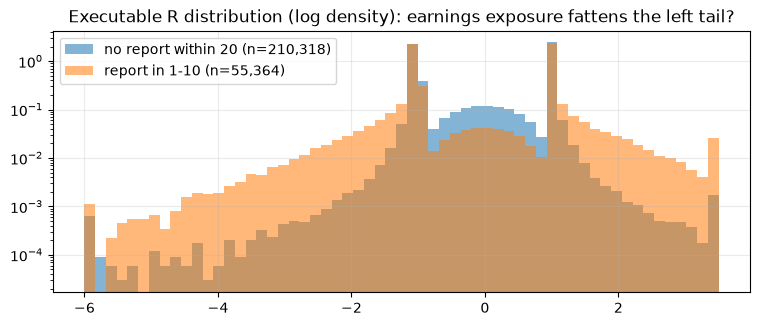

share of trades losing more than 2R: exposed 2.29% vs not exposed 0.14%


In [8]:
# tails: distribution of executable R, exposed (report in 1..10) vs not exposed (no report within 20)
ex = EC[(EC.next_rep_sessions_retro>=1)&(EC.next_rep_sessions_retro<=10)].exec_r_net_1r
ne = EC[EC.bucket=="no report within 20"].exec_r_net_1r
bins = np.linspace(-6, 3.5, 60)
plt.hist(ne.clip(-6,3.5), bins, density=True, alpha=.55, label=f"no report within 20 (n={len(ne):,})")
plt.hist(ex.clip(-6,3.5), bins, density=True, alpha=.55, label=f"report in 1-10 (n={len(ex):,})")
plt.yscale("log"); plt.legend(); plt.title("Executable R distribution (log density): earnings exposure fattens the left tail?"); plt.show()
print("share of trades losing more than 2R: exposed %.2f%% vs not exposed %.2f%%" % ((ex<=-2).mean()*100, (ne<=-2).mean()*100))

In [9]:
# PIT-safe projection vs retrospective date: how good is 'last report + 91 days'?
err = (EC.next_rep_sessions_proj - EC.next_rep_sessions_retro)
m = EC.next_rep_sessions_retro.between(0, 30)
print("projection error in sessions where the real report is within 30 sessions: median %.0f, |err|<=3: %.1f%%, |err|<=5: %.1f%%" % (err[m].median(), (err[m].abs()<=3).mean()*100, (err[m].abs()<=5).mean()*100))
pe = EC.next_rep_sessions_proj.between(1,10); re_ = EC.next_rep_sessions_retro.between(1,10)
print("agreement on 'report in 1-10': both %d, proj only %d, retro only %d, neither %d" % ((pe&re_).sum(), (pe&~re_).sum(), (~pe&re_).sum(), (~pe&~re_).sum()))

projection error in sessions where the real report is within 30 sessions: median 0, |err|<=3: 54.0%, |err|<=5: 67.2%
agreement on 'report in 1-10': both 32719, proj only 14671, retro only 22645, neither 289543


In [10]:
# holding-period exposure (DESCRIPTIVE ONLY: the window depends on the outcome, longer trades mechanically meet more reports)
kk = EC.next_rep_sessions_retro
EC["hold_exposed"] = (kk>=1) & (kk <= EC.bars_1r)
d = EC.groupby(["dir","hold_exposed"]).agg(n=("exec_r_net_1r","size"), mean_R=("exec_r_net_1r","mean"), bars=("bars_1r","mean"), gap_stop=("gap_stop_1r","mean"), le_m2=("exec_r_net_1r", lambda s: (s<=-2).mean()*100))
print("Report inside the ACTUAL holding period (outcome-conditioned, not a usable filter):"); print(d.round(3).to_string())

Report inside the ACTUAL holding period (outcome-conditioned, not a usable filter):
                           n  mean_R   bars  gap_stop  le_m2
dir     hold_exposed                                        
bearish False         144192  -0.094 10.102     0.051  0.161
        True           23491  -0.082 10.681     0.145  2.801
bullish False         162796  -0.013  8.575     0.047  0.124
        True           29099   0.010  9.301     0.132  3.234


## 5. Track 2 — Market regime (entry-time only)

In [11]:
RG = B[B.ew_trend_up.notna()].copy()
RG["trend_aligned"] = np.where(RG.direction==1, RG.ew_trend_up==True, RG.ew_trend_up==False)
RG["breadth_aligned"] = np.where(RG.direction==1, RG.breadth50>0.5, RG.breadth50<0.5)
vq = RG[RG.period=="discovery"].drop_duplicates("date").ew_vol20.quantile([1/3, 2/3]).to_numpy()   # thresholds fixed on discovery days only
RG["vol_tercile"] = pd.cut(RG.ew_vol20, [-np.inf, vq[0], vq[1], np.inf], labels=["low vol","mid vol","high vol"])
print("realised-vol tercile thresholds (annualised %%, discovery days): %.1f / %.1f" % tuple(vq))
def by(df, col, metric="exec_r_net_1r"):
    rows = []
    for (per, dn, v), g in df.groupby(["period","dir",col], observed=True):
        m, lo, hi, n = LB.boot_mean(g[metric], g.date)
        rows.append({"period": per, "dir": dn, col: v, "n": n, "mean_R": m, "ci_lo": lo, "ci_hi": hi, "es5": LB.tail_stats(g[metric])["es5"]})
    return pd.DataFrame(rows).set_index(["period","dir",col])
for c in ["trend_aligned","breadth_aligned","vol_tercile"]:
    print(); print("--", c); print(by(RG, c).round(3).to_string())

realised-vol tercile thresholds (annualised %, discovery days): 18.1 / 23.2

-- trend_aligned


                                      n  mean_R  ci_lo  ci_hi    es5
period    dir     trend_aligned                                     
discovery bearish False           27241   0.068 -0.004  0.147 -1.297
                  True            58525  -0.090 -0.165 -0.019 -1.280
          bullish False           31165   0.008 -0.080  0.087 -1.344
                  True            56005  -0.028 -0.099  0.047 -1.406
oos       bearish False           82987  -0.144 -0.190 -0.095 -1.566
                  True             9053  -0.072 -0.332  0.225 -1.247
          bullish False            4407   0.145 -0.061  0.280 -1.457
                  True           111400  -0.010 -0.038  0.018 -1.491

-- breadth_aligned


                                       n  mean_R  ci_lo  ci_hi    es5
period    dir     breadth_aligned                                    
discovery bearish False            15399   0.138  0.046  0.224 -1.313
                  True             70367  -0.079 -0.143 -0.016 -1.279
          bullish False            26954  -0.084 -0.160 -0.015 -1.378
                  True             60216   0.016 -0.052  0.088 -1.385
oos       bearish False            45176  -0.089 -0.133 -0.040 -1.530
                  True             46864  -0.183 -0.264 -0.096 -1.540
          bullish False            17701   0.034 -0.023  0.091 -1.529
                  True             98106  -0.011 -0.045  0.021 -1.483

-- vol_tercile


                                   n  mean_R  ci_lo  ci_hi    es5
period    dir     vol_tercile                                    
discovery bearish low vol      33742   0.047 -0.031  0.123 -1.331
                  mid vol      25513  -0.083 -0.204  0.031 -1.333
                  high vol     26511  -0.109 -0.210 -0.004 -1.180
          bullish low vol      27213  -0.126 -0.199 -0.056 -1.512
                  mid vol      34877   0.036 -0.067  0.128 -1.347
                  high vol     25080   0.033 -0.073  0.140 -1.295
oos       bearish low vol      60536  -0.085 -0.142 -0.030 -1.563
                  mid vol      24376  -0.195 -0.275 -0.113 -1.513
                  high vol      7128  -0.378 -0.588 -0.070 -1.387
          bullish low vol      69944  -0.012 -0.050  0.027 -1.511
                  mid vol      39382  -0.019 -0.065  0.028 -1.451
                  high vol      6481   0.165  0.033  0.282 -1.504


In [12]:
# VIX: only 2025-09-18 onward -> exploratory, thresholds from that same window (no OOS possible)
VX = B[B.vix.notna()].copy()
vt = VX.drop_duplicates("date").vix.quantile([1/3, 2/3]).to_numpy()
VX["vix_tercile"] = pd.cut(VX.vix, [-np.inf, vt[0], vt[1], np.inf], labels=["low","mid","high"])
print("VIX window %s -> %s, %d breakouts, %d days; tercile cut points %.1f / %.1f (EXPLORATORY)" % (VX.date.min().date(), VX.date.max().date(), len(VX), VX.date.nunique(), *vt))
rows=[]
for (dn, v), g in VX.groupby(["dir","vix_tercile"], observed=True):
    m, lo, hi, n = LB.boot_mean(g.exec_r_net_1r, g.date); rows.append({"dir": dn, "vix": v, "n": n, "mean_R": m, "ci_lo": lo, "ci_hi": hi})
print(pd.DataFrame(rows).set_index(["dir","vix"]).round(3).to_string())

VIX window 2025-09-18 -> 2026-09-22, 83985 breakouts, 254 days; tercile cut points 16.4 / 18.4 (EXPLORATORY)
                  n  mean_R  ci_lo  ci_hi
dir     vix                              
bearish low   10320   0.079 -0.009  0.154
        mid   12152   0.017 -0.097  0.121
        high  15511  -0.329 -0.411 -0.241
bullish low   16303  -0.023 -0.079  0.031
        mid   16937  -0.053 -0.107  0.005
        high  12762   0.090  0.004  0.170


## 6. Track 3 — Sector strength (modern membership: **biased, exploratory**)
`sec_rel` = the sector's 20-session equal-weight return minus the universe's, computed from prices up to t. Sector membership is **today's** classification projected backwards. `stock_vs_sector` = the stock's own 20-session return minus its sector's. "Aligned" means the strength points the same way as the trade.

In [13]:
SC = B[B.sec_rel.notna() & (B.sec_n >= 20)].copy()
SC["sector_aligned"] = (SC.sec_rel * SC.direction) > 0
SC["stock_vs_sector_aligned"] = (SC.stock_vs_sector * SC.direction) > 0
for c in ["sector_aligned","stock_vs_sector_aligned"]:
    print(); print("--", c, "(modern-membership biased)"); print(by(SC, c).round(3).to_string())


-- sector_aligned (modern-membership biased)


                                      n  mean_R  ci_lo  ci_hi    es5
period    dir     sector_aligned                                    
discovery bearish False           32401  -0.038 -0.097  0.023 -1.266
                  True            53293  -0.041 -0.101  0.018 -1.297
          bullish False           34733  -0.035 -0.098  0.030 -1.389
                  True            52324  -0.002 -0.057  0.050 -1.381
oos       bearish False           30578  -0.123 -0.176 -0.068 -1.631
                  True            61366  -0.143 -0.193 -0.093 -1.490
          bullish False           46010  -0.004 -0.042  0.031 -1.450
                  True            69624  -0.005 -0.036  0.026 -1.517

-- stock_vs_sector_aligned (modern-membership biased)


                                                n  mean_R  ci_lo  ci_hi    es5
period    dir     stock_vs_sector_aligned                                     
discovery bearish False                     11970  -0.143 -0.225 -0.057 -1.324
                  True                      73724  -0.023 -0.076  0.030 -1.279
          bullish False                     14243   0.010 -0.080  0.096 -1.431
                  True                      72814  -0.020 -0.072  0.030 -1.375
oos       bearish False                      6392  -0.184 -0.312 -0.057 -1.445
                  True                      85552  -0.133 -0.179 -0.085 -1.544
          bullish False                     14636  -0.073 -0.117 -0.030 -1.631
                  True                     100998   0.005 -0.023  0.032 -1.469


## 7. Confirmatory family: 10 hypotheses × 2 directions, Holm on discovery, replication on OOS

In [14]:
F = B.copy()
k = F.next_rep_sessions_retro; kp = F.next_rep_sessions_proj
H = {
 "H1 report in 1-5 (retro)":        (F.covered, k.between(1,5)),
 "H2 report in 1-10 (retro)":       (F.covered, k.between(1,10)),
 "H3 report in 1-20 (retro)":       (F.covered, k.between(1,20)),
 "H4 post-earnings breakout":       (F.covered, (k==0) | (F.last_rep_sessions<=3)),
 "H5 report in 1-10 (proj, PIT)":   (F.covered, kp.between(1,10)),
 "H6 EW trend aligned":             (F.ew_trend_up.notna(), np.where(F.direction==1, F.ew_trend_up==True, F.ew_trend_up==False)),
 "H7 breadth aligned":              (F.breadth50.notna(), np.where(F.direction==1, F.breadth50>0.5, F.breadth50<0.5)),
 "H8 high realised vol":            (F.ew_vol20.notna(), F.ew_vol20 > vq[1]),
 "H9 sector aligned (modern)":      (F.sec_rel.notna() & (F.sec_n>=20), (F.sec_rel*F.direction)>0),
 "H10 stock vs sector aligned (modern)": (F.stock_vs_sector.notna() & F.sec_rel.notna(), (F.stock_vs_sector*F.direction)>0),
}
rows = []
for name, (valid, mask) in H.items():
    mask = pd.Series(np.asarray(mask, bool), index=F.index)
    for dn in ["bullish","bearish"]:
        for per in ["discovery","oos"]:
            sel = valid & (F.dir==dn) & (F.period==per)
            g = F[sel]; mm = mask[sel]
            diff, lo, hi, p, na, nb = LB.boot_diff(g.exec_r_net_1r, mm, g.date)
            sd = g.exec_r_net_1r.std()
            rows.append({"hypothesis": name, "dir": dn, "period": per, "diff_R": diff, "ci_lo": lo, "ci_hi": hi, "p": p, "effect_d": diff/sd if sd else np.nan, "n_flag": na, "n_rest": nb, "flag_share%": na/(na+nb)*100 if na+nb else np.nan})
R7 = pd.DataFrame(rows)
disc = R7[R7.period=="discovery"].copy(); disc["p_holm"] = LB.holm(disc.p.fillna(1).to_numpy())
oos = R7[R7.period=="oos"].set_index(["hypothesis","dir"])
disc = disc.set_index(["hypothesis","dir"])
disc["oos_diff"] = oos.diff_R; disc["oos_lo"] = oos.ci_lo; disc["oos_hi"] = oos.ci_hi; disc["oos_p"] = oos.p
disc["verdict"] = np.where((disc.p_holm<0.05) & (np.sign(disc.diff_R)==np.sign(disc.oos_diff)) & (disc.oos_p<0.05), "SUPPORTED",
                   np.where((disc.p_holm<0.05), "discovery only", np.where(disc.oos_p<0.05, "OOS only (exploratory)", "not supported")))
print("Difference in mean executable R (flag TRUE minus FALSE), within direction. p = day-cluster bootstrap, Holm over 20 tests.")
print(disc[["n_flag","flag_share%","diff_R","ci_lo","ci_hi","p","p_holm","effect_d","oos_diff","oos_lo","oos_hi","oos_p","verdict"]].round(3).to_string())

Difference in mean executable R (flag TRUE minus FALSE), within direction. p = day-cluster bootstrap, Holm over 20 tests.
                                              n_flag  flag_share%  diff_R  ci_lo  ci_hi     p  p_holm  effect_d  oos_diff  oos_lo  oos_hi  oos_p                 verdict
hypothesis                           dir                                                                                                                                
H1 report in 1-5 (retro)             bullish    7715        9.338   0.043 -0.020  0.108 0.179   1.000     0.042    -0.018  -0.060   0.025  0.429           not supported
                                     bearish    5672        7.074  -0.038 -0.104  0.030 0.293   1.000    -0.038    -0.029  -0.097   0.044  0.447           not supported
H2 report in 1-10 (retro)            bullish   14717       17.813   0.070 -0.001  0.139 0.055   0.825     0.068    -0.021  -0.065   0.021  0.332           not supported
                                 

## 8. Track 4 — Combined filters vs the unfiltered baseline
Filters are declared in advance, with no tuning. **Coverage cost** = the share of baseline trades the filter removes.
* `E` = no report in 1–10 sessions (retro). `Ep` = the same with the PIT projection.
* `T` = equal-weight trend aligned with the trade.
* `S` = sector aligned (modern membership, biased).
* `L` = long only (shown because the earlier Lab work found the short side weakest).

In [15]:
G = B[B.covered & B.ew_trend_up.notna() & B.sec_rel.notna() & (B.sec_n>=20)].copy()
k = G.next_rep_sessions_retro; kp = G.next_rep_sessions_proj
fl = {
 "E":  ~k.between(1,10), "Ep": ~kp.between(1,10),
 "T":  pd.Series(np.where(G.direction==1, G.ew_trend_up==True, G.ew_trend_up==False), index=G.index),
 "S":  (G.sec_rel*G.direction)>0, "L": G.direction==1,
}
combos = {"baseline": pd.Series(True, index=G.index), "E": fl["E"], "Ep": fl["Ep"], "T": fl["T"], "S": fl["S"],
          "E&T": fl["E"]&fl["T"], "E&S": fl["E"]&fl["S"], "T&S": fl["T"]&fl["S"], "E&T&S": fl["E"]&fl["T"]&fl["S"], "Ep&T&S (PIT earnings)": fl["Ep"]&fl["T"]&fl["S"],
          "L": fl["L"], "L&E": fl["L"]&fl["E"], "L&E&T": fl["L"]&fl["E"]&fl["T"], "L&Ep&T&S": fl["L"]&fl["Ep"]&fl["T"]&fl["S"]}
rows = []
for name, mk in combos.items():
    for per in ["discovery","oos"]:
        base = G[G.period==per]; g = base[mk[base.index]]
        m, lo, hi, n = LB.boot_mean(g.exec_r_net_1r, g.date); ts = LB.tail_stats(g.exec_r_net_1r)
        yrs = g.groupby("year").exec_r_net_1r.mean()
        rows.append({"filter": name, "period": per, "n": n, "kept%": n/len(base)*100, "trades/day": g.groupby("date").size().median(),
                     "mean_R": m, "ci_lo": lo, "ci_hi": hi, "sharpe/trade": ts["mean"]/ts["std"], "es5": ts["es5"], "<=-1.5R %": ts["share_le_-1.5R"],
                     "pos_years": f"{(yrs>0).sum()}/{len(yrs)}", "mean_R_3r_exit": g.exec_r_net_3r.mean()})
T8 = pd.DataFrame(rows).set_index(["filter","period"])
print(T8.round(3).to_string())

                                      n   kept%  trades/day  mean_R  ci_lo  ci_hi  sharpe/trade    es5  <=-1.5R % pos_years  mean_R_3r_exit
filter                period                                                                                                               
baseline              discovery  162721 100.000     223.000  -0.028 -0.065  0.008        -0.028 -1.338      0.884       1/3          -0.042
                      oos        196654 100.000     251.000  -0.064 -0.092 -0.038        -0.062 -1.515      1.496       0/3          -0.080
E                     discovery  136948  84.161     189.000  -0.034 -0.074  0.005        -0.035 -1.214      0.432       1/3          -0.045
                      oos        167099  84.971     212.000  -0.060 -0.088 -0.033        -0.060 -1.308      0.741       0/3          -0.078
Ep                    discovery  140045  86.064     195.500  -0.035 -0.071  0.005        -0.035 -1.257      0.578       1/3          -0.041
                    

      baseline      E      T  E&T&S      L  L&E&T
year                                             
2021    -0.091 -0.110 -0.133 -0.132 -0.072 -0.118
2022    -0.068 -0.103 -0.117 -0.136 -0.105 -0.537
2023     0.028  0.054  0.004  0.063  0.068  0.086
2024    -0.098 -0.098 -0.016 -0.032 -0.016 -0.030
2025    -0.061 -0.053 -0.036 -0.008 -0.008 -0.001
2026    -0.030 -0.025  0.009  0.009  0.009  0.014


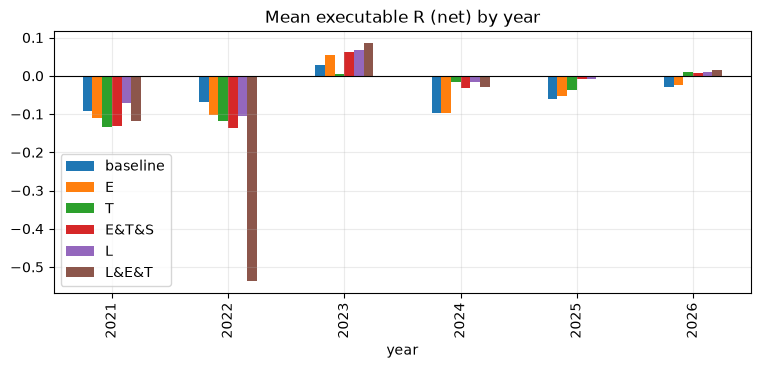

In [16]:
# year by year for the most relevant filters (OOS years are 2024+)
yy = pd.DataFrame({name: G[combos[name]].groupby("year").exec_r_net_1r.mean() for name in ["baseline","E","T","E&T&S","L","L&E&T"]})
print(yy.round(3).to_string()); yy.plot.bar(title="Mean executable R (net) by year"); plt.axhline(0, c="k", lw=.8); plt.show()

## 9. Live window check (signal ledger, short and censored)

In [17]:
LG = pd.read_csv("data/signal_ledger.csv", parse_dates=["signal_date"])
SESS = LB.session_index(P)
lf = LB.earnings_features(LG.rename(columns={"signal_date":"date"})[["symbol","date","direction"]].reset_index(drop=True), E, SESS)
LG = LG.join(lf)
LG["exposed10"] = LG.next_rep_sessions_retro.between(1,10)
sess = np.sort(LG.signal_date.unique()); LG["age"] = LG.signal_date.map({d: len(sess)-1-i for i, d in enumerate(sess)})
rows=[]
for kk in (3,5,8):
    d = LG[LG.age>=kk].copy(); res = d.status.isin(["stopped","target1","target2","target3","expired"])
    d["locked"] = np.where(res & (d.bars_held<=kk), d.outcome_r, 0.0)
    for f_, g in d.groupby("exposed10"):
        m, lo, hi, n = LB.boot_mean(g.locked, g.signal_date); rows.append({"k": kk, "report in 1-10": f_, "n": n, "locked_R": m, "ci_lo": lo, "ci_hi": hi})
print("Ledger, R locked in by session k (censoring-corrected), split by earnings exposure:"); print(pd.DataFrame(rows).set_index(["k","report in 1-10"]).round(3).to_string())
print("ledger signals with a report in 1-10 sessions: %.1f%%" % (LG.exposed10.mean()*100))

Ledger, R locked in by session k (censoring-corrected), split by earnings exposure:
                     n  locked_R  ci_lo  ci_hi
k report in 1-10                              
3 False           1267    -0.002 -0.038  0.017
  True            1158     0.085  0.027  0.143
5 False           1252    -0.029 -0.097  0.017
  True             739     0.191  0.122  0.277
8 False           1230    -0.066 -0.132 -0.015
  True             275     0.218 -0.105  0.440
ledger signals with a report in 1-10 sessions: 54.9%


## 10. Results, implications and GO / NO-GO

In [18]:
print("Confirmatory verdicts:"); print(disc.verdict.groupby(level=0).apply(lambda s: dict(s.droplevel(0))).to_string())

Confirmatory verdicts:
hypothesis                                   
H1 report in 1-5 (retro)              bullish             not supported
                                      bearish             not supported
H10 stock vs sector aligned (modern)  bullish    OOS only (exploratory)
                                      bearish            discovery only
H2 report in 1-10 (retro)             bullish             not supported
                                      bearish    OOS only (exploratory)
H3 report in 1-20 (retro)             bullish             not supported
                                      bearish    OOS only (exploratory)
H4 post-earnings breakout             bullish             not supported
                                      bearish             not supported
H5 report in 1-10 (proj, PIT)         bullish            discovery only
                                      bearish             not supported
H6 EW trend aligned                   bullish             not suppo

### Findings (2026-10-21 pull; window 2021-09 → 2026-09; 380,783 executable breakouts)

1. **Executed honestly, the strategy loses.** For the live plan (next-open entry, gap-aware, 10 bps): discovery −0.027 R [−0.064, +0.012], **OOS −0.063 R [−0.089, −0.036]**. Longs are ≈ 0 (−0.015 / −0.004). Shorts lose (−0.040 / **−0.137**). Execution costs about 0.04–0.07 R against the dataset's close-entry, no-gap `r_single`, which was the source of the "+0.05 R bullish" backtest figure.
2. **Earnings is a tail-risk variable, not a return variable.** A report 1–5 sessions after entry barely moves mean R (H1–H3 not supported). It does multiply the left tail: 5.7% of trades lose ≥ 1.5R versus 0.35% with no report, the 5% expected shortfall is −2.33R versus −1.20R, 13% gap through the stop versus 5%, and 2.3% lose > 2R versus 0.14% (16×). Upside gaps through the target offset the mean, so the average hides the risk.
3. **A point-in-time-safe schedule is not available historically.** All 61,265 historical rows were fetched after the event. The "last report + 91 days" projection has a median error of 0 sessions but is within ±3 sessions only 54% of the time. A forward-observed (first-seen) date log would be needed to validate a known-at-entry filter. That is a future collector/migration decision and out of scope here.
4. **Regime: one supported result, and it points against shorts.** Bearish breakouts taken when breadth is weak (< 50% of stocks above their 50-day average) do worse: −0.217 R in discovery (Holm p = 0.01) and −0.094 R OOS (p = 0.04). Trend alignment points the same way for shorts (Holm p = 0.051). No regime split makes shorts positive OOS. VIX and realised vol: high volatility looks bad for shorts and good for longs, but this is **exploratory** (VIX has 1 year only; the realised-vol OOS result rests on few days).
5. **Sector strength explains nothing.** Sector alignment is not supported in either direction, and the stock-vs-sector result flips between periods. The data is also not point-in-time (modern membership).
6. **No combined filter turns the strategy positive.** The best OOS combinations reach about −0.01 R (E&T, E&T&S, T&S, L&Ep&T&S), with confidence intervals spanning zero, at a cost of 50–70% of trades. The earnings filter E removes 15% of trades, leaves mean R unchanged, and **halves the share of ≥ 1.5R losses** (1.50% → 0.74% OOS).
7. **The live ledger (14 sessions, earnings season) points the other way** (exposed trades +0.19 R locked by session 5). This is one earnings season with 55% of signals exposed: anecdotal, not evidence.